# KI-Labor – Assignment 5: Object Detection (Penn-Fudan)

Ausgeführt auf dem DACHS-Cluster (Partition `gpu1`, NVIDIA L40S), Slurm-Job 149643, Laufzeit des ganzen Notebooks 64 s.

In [1]:
import os
import random
import time
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision.io import ImageReadMode, read_image
from torchvision.models.detection import (
    FasterRCNN_MobileNet_V3_Large_320_FPN_Weights,
    fasterrcnn_mobilenet_v3_large_320_fpn,
)
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.ops import box_iou, masks_to_boxes
from torchvision.utils import draw_bounding_boxes, draw_segmentation_masks

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

print(f"PyTorch {torch.__version__} | Gerät: {DEVICE}")

PyTorch 2.15.0+cu132 | Gerät: cuda


## 1. Datensatz laden und ansehen

Penn-Fudan enthält Straßenszenen mit Fußgängern. Zu jedem Bild gibt es eine Instanzmaske: Pixelwert 0 ist Hintergrund, 1, 2, … sind die einzelnen Personen.

In [2]:
DATA_ROOT = "./data"
URL = "https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip"
ROOT = os.path.join(DATA_ROOT, "PennFudanPed")

if not os.path.isdir(ROOT):
    os.makedirs(DATA_ROOT, exist_ok=True)
    zip_path = os.path.join(DATA_ROOT, "PennFudanPed.zip")
    urllib.request.urlretrieve(URL, zip_path)
    with zipfile.ZipFile(zip_path) as zf:
        zf.extractall(DATA_ROOT)
print("Penn-Fudan bereit:", sorted(os.listdir(ROOT)))

Penn-Fudan bereit: ['Annotation', 'PNGImages', 'PedMasks', 'added-object-list.txt', 'readme.txt']


In [3]:
image_files = sorted(os.listdir(os.path.join(ROOT, "PNGImages")))
mask_files = sorted(os.listdir(os.path.join(ROOT, "PedMasks")))

sizes, instances = [], []
for mask_file in mask_files:
    mask = read_image(os.path.join(ROOT, "PedMasks", mask_file))
    sizes.append(tuple(mask.shape[1:]))
    instances.append(len(torch.unique(mask)) - 1)
heights, widths = zip(*sizes)

print(f"Bilder: {len(image_files)} | Masken: {len(mask_files)}")
print(f"Fußgänger-Instanzen: {sum(instances)} ({min(instances)}–{max(instances)} pro Bild, "
      f"Mittel {np.mean(instances):.2f})")
print(f"Breite: {min(widths)}–{max(widths)} px, Höhe: {min(heights)}–{max(heights)} px, "
      f"{len(set(sizes))} verschiedene Größen")
with open(os.path.join(ROOT, "added-object-list.txt")) as f:
    added = sum(1 for line in f if line.strip() and not line.startswith("#"))
print(f"davon nachträglich gelabelt (added-object-list.txt): {added} → ursprüngliche Annotation: {sum(instances) - added}")

Bilder: 170 | Masken: 170
Fußgänger-Instanzen: 423 (1–8 pro Bild, Mittel 2.49)
Breite: 253–1017 px, Höhe: 311–581 px, 170 verschiedene Größen
davon nachträglich gelabelt (added-object-list.txt): 78 → ursprüngliche Annotation: 345


Die Folien nennen 345 Fußgänger, das ist der Stand der Originalveröffentlichung. In der aktuellen Version wurden zusätzlich kleine und stark verdeckte Personen gelabelt (`added-object-list.txt`), die Masken enthalten deshalb mehr Instanzen. Verwendet werden alle Instanzen aus den Masken.

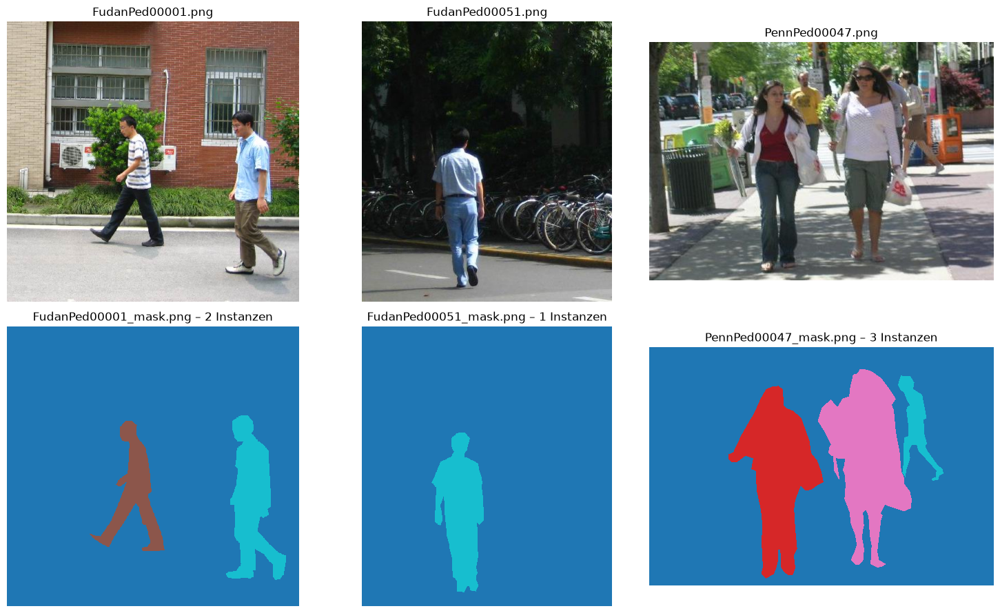

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for col, idx in enumerate([0, 50, 120]):
    image = read_image(os.path.join(ROOT, "PNGImages", image_files[idx]), ImageReadMode.RGB)
    mask = read_image(os.path.join(ROOT, "PedMasks", mask_files[idx]))[0]
    axes[0, col].imshow(image.permute(1, 2, 0))
    axes[0, col].set_title(image_files[idx])
    axes[1, col].imshow(mask, cmap="tab10", interpolation="nearest")
    axes[1, col].set_title(f"{mask_files[idx]} – {len(torch.unique(mask)) - 1} Instanzen")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Dataset mit Detection-Targets

Für jede Instanz-ID wird eine Binärmaske gebildet, `masks_to_boxes` liefert daraus die Box `(xmin, ymin, xmax, ymax)`. Label 0 ist in torchvision für den Hintergrund reserviert, Fußgänger bekommen deshalb Label 1. Mit `train=True` wird zufällig horizontal gespiegelt, Bild und Boxen konsistent (optionale Erweiterung).

In [5]:
class PennFudanDataset(Dataset):
    def __init__(self, root, train=False):
        self.root = root
        self.train = train
        self.images = sorted(os.listdir(os.path.join(root, "PNGImages")))
        self.masks = sorted(os.listdir(os.path.join(root, "PedMasks")))

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image = read_image(os.path.join(self.root, "PNGImages", self.images[idx]), ImageReadMode.RGB)
        mask = read_image(os.path.join(self.root, "PedMasks", self.masks[idx]))[0]

        obj_ids = torch.unique(mask)[1:]
        masks = mask == obj_ids[:, None, None]
        boxes = masks_to_boxes(masks)

        image = image.float() / 255
        if self.train and random.random() < 0.5:
            width = image.shape[-1]
            image = image.flip(-1)
            boxes = boxes[:, [2, 1, 0, 3]] * torch.tensor([-1, 1, -1, 1]) + torch.tensor([width, 0, width, 0])

        target = {
            "boxes": boxes,
            "labels": torch.ones(len(obj_ids), dtype=torch.int64),
            "image_id": idx,
            "area": (boxes[:, 3] - boxes[:, 1]) * (boxes[:, 2] - boxes[:, 0]),
            "iscrowd": torch.zeros(len(obj_ids), dtype=torch.int64),
        }
        return image, target


def collate_fn(batch):
    return tuple(zip(*batch))


image, target = PennFudanDataset(ROOT)[0]
print("Bild:", tuple(image.shape), image.dtype, f"[{image.min():.2f}, {image.max():.2f}]")
for key, value in target.items():
    print(f"{key:9s}", value)

Bild: (3, 536, 559) torch.float32 [0.00, 1.00]
boxes     tensor([[159., 181., 301., 430.],
        [419., 170., 534., 485.]])
labels    tensor([1, 1])
image_id  0
area      tensor([35358., 36225.])
iscrowd   tensor([0, 0])


## 3. Ground-Truth-Boxen aus den Masken

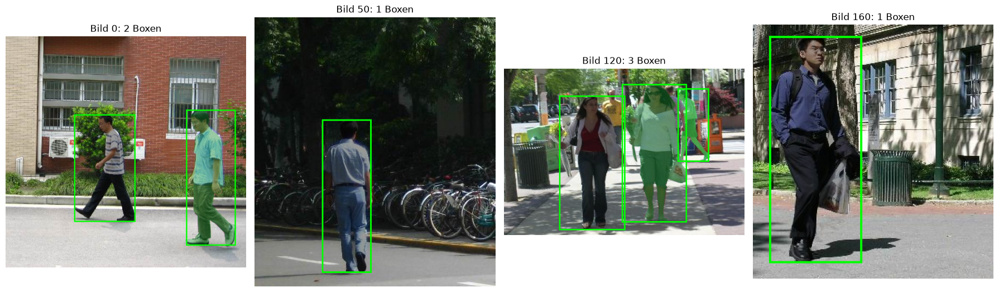

In [6]:
def show_boxes(image, boxes, labels=None, colors="lime", title="", ax=None):
    canvas = draw_bounding_boxes((image * 255).to(torch.uint8), boxes, labels=labels, colors=colors, width=3)
    ax = ax or plt.gca()
    ax.imshow(canvas.permute(1, 2, 0))
    ax.set_title(title)
    ax.axis("off")


full_dataset = PennFudanDataset(ROOT)
fig, axes = plt.subplots(1, 4, figsize=(18, 6))
for ax, idx in zip(axes, [0, 50, 120, 160]):
    image, target = full_dataset[idx]
    mask = read_image(os.path.join(ROOT, "PedMasks", full_dataset.masks[idx]))[0]
    masks = mask == torch.unique(mask)[1:, None, None]
    overlay = draw_segmentation_masks((image * 255).to(torch.uint8), masks, alpha=0.4).float() / 255
    show_boxes(overlay, target["boxes"], title=f"Bild {idx}: {len(target['boxes'])} Boxen", ax=ax)
plt.tight_layout()
plt.show()

## 4. Inferenz mit dem COCO-vortrainierten Detektor

Der Detektor kennt die 91 COCO-Kategorien, Fußgänger entsprechen der Klasse `person`. Er bekommt eine Liste von Bildern unterschiedlicher Größe und skaliert intern (bei diesem Modell auf 320 px).

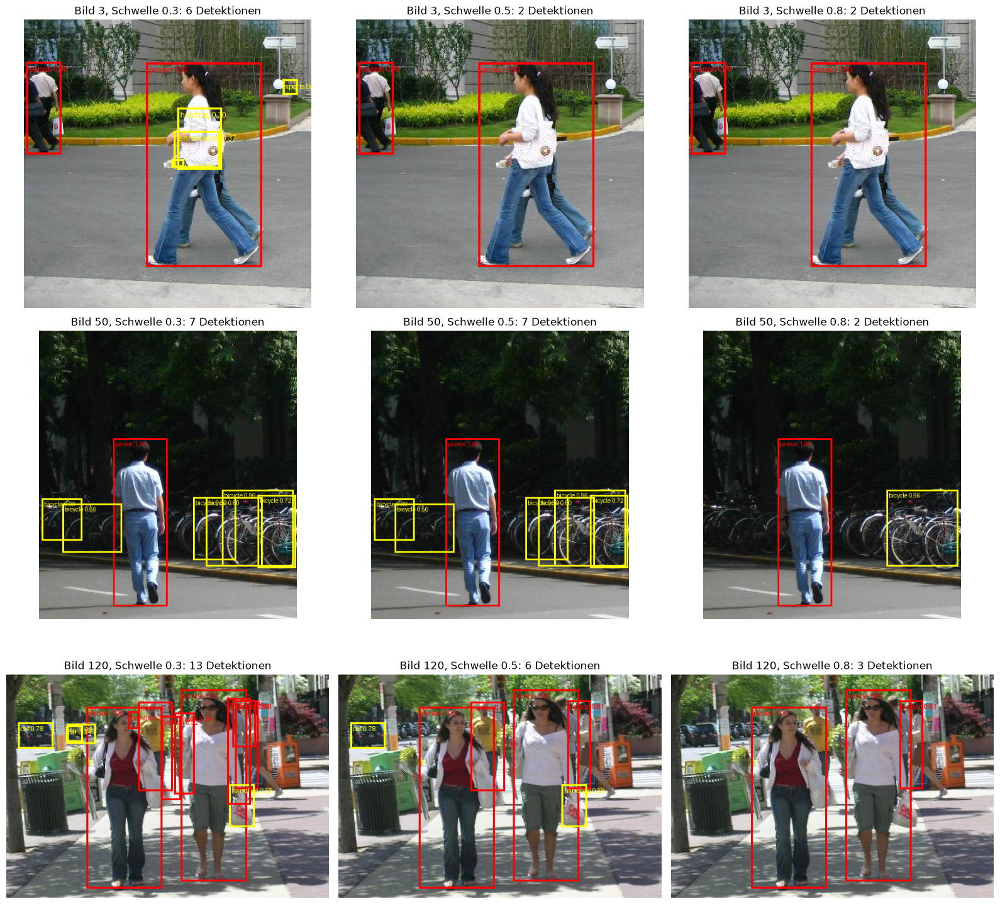

In [7]:
coco_weights = FasterRCNN_MobileNet_V3_Large_320_FPN_Weights.DEFAULT
coco_model = fasterrcnn_mobilenet_v3_large_320_fpn(weights=coco_weights, box_score_thresh=0.0).eval().to(DEVICE)
COCO_NAMES = coco_weights.meta["categories"]
PERSON = COCO_NAMES.index("person")
THRESHOLDS = [0.3, 0.5, 0.8]


@torch.inference_mode()
def predict(model, images):
    return [{k: v.cpu() for k, v in p.items()} for p in model([img.to(DEVICE) for img in images])]


demo_ids = [3, 50, 120]
demo_images = [full_dataset[i][0] for i in demo_ids]
demo_preds = predict(coco_model, demo_images)

fig, axes = plt.subplots(len(demo_ids), len(THRESHOLDS), figsize=(16, 5 * len(demo_ids)))
for row, (image, pred) in enumerate(zip(demo_images, demo_preds)):
    for col, thr in enumerate(THRESHOLDS):
        keep = pred["scores"] >= thr
        labels = [f"{COCO_NAMES[l]} {s:.2f}" for l, s in zip(pred["labels"][keep], pred["scores"][keep])]
        colors = ["red" if l == PERSON else "yellow" for l in pred["labels"][keep]]
        show_boxes(image, pred["boxes"][keep], labels, colors,
                   f"Bild {demo_ids[row]}, Schwelle {thr}: {keep.sum()} Detektionen", axes[row, col])
plt.tight_layout()
plt.show()

Precision und Recall der Klasse `person` über alle 170 Bilder bei IoU ≥ 0,5: Jede Ground-Truth-Box darf höchstens einmal gematcht werden (Vorhersagen nach Score sortiert), weitere Treffer auf dieselbe Person zählen als False Positive.

In [8]:
def match(pred_boxes, pred_scores, gt_boxes, iou_thr=0.5):
    """Greedy-Matching nach Score: liefert pro Vorhersage TP (True/False) und die IoU zur gematchten GT-Box."""
    order = pred_scores.argsort(descending=True)
    ious = box_iou(pred_boxes[order], gt_boxes) if len(gt_boxes) else torch.zeros(len(order), 0)
    taken = torch.zeros(len(gt_boxes), dtype=torch.bool)
    tp, best = torch.zeros(len(order), dtype=torch.bool), torch.zeros(len(order))
    for i in range(len(order)):
        if ious.shape[1] == 0:
            continue
        best_iou, j = ious[i].max(0)
        best[i] = best_iou
        if best_iou >= iou_thr and not taken[j]:
            taken[j] = True
            tp[i] = True
    inv = order.argsort()
    return tp[inv], best[inv]


def average_precision(preds, targets, iou_thr=0.5):
    """AP@0.5 (VOC-Stil, alle Punkte) über einen ganzen Split."""
    scores, tps, n_gt = [], [], 0
    for pred, target in zip(preds, targets):
        tp, _ = match(pred["boxes"], pred["scores"], target["boxes"], iou_thr)
        scores.append(pred["scores"])
        tps.append(tp)
        n_gt += len(target["boxes"])
    order = torch.cat(scores).argsort(descending=True)
    tp = torch.cat(tps)[order].float()
    recall = tp.cumsum(0) / n_gt
    precision = tp.cumsum(0) / torch.arange(1, len(tp) + 1)
    precision = torch.flip(torch.cummax(torch.flip(precision, [0]), 0).values, [0])
    recall = torch.cat([torch.zeros(1), recall])
    return float(((recall[1:] - recall[:-1]) * precision).sum())


def pr_table(preds, targets, thresholds=THRESHOLDS):
    rows = []
    for thr in thresholds:
        tp = fp = n_gt = 0
        for pred, target in zip(preds, targets):
            keep = pred["scores"] >= thr
            hits, _ = match(pred["boxes"][keep], pred["scores"][keep], target["boxes"])
            tp += int(hits.sum())
            fp += int((~hits).sum())
            n_gt += len(target["boxes"])
        rows.append({"Schwelle": thr, "Detektionen": tp + fp, "TP": tp, "FP": fp, "FN": n_gt - tp,
                     "Precision": tp / max(tp + fp, 1), "Recall": tp / n_gt})
    return pd.DataFrame(rows).set_index("Schwelle")


def only_person(pred):
    keep = pred["labels"] == PERSON
    return {k: v[keep] for k, v in pred.items()}


all_targets = [full_dataset[i][1] for i in range(len(full_dataset))]
coco_preds = []
for start in range(0, len(full_dataset), 8):
    coco_preds += predict(coco_model, [full_dataset[i][0] for i in range(start, min(start + 8, len(full_dataset)))])
coco_person = [only_person(p) for p in coco_preds]

print(f"COCO-Modell, Klasse person, alle 170 Bilder: AP@0.5 = {average_precision(coco_person, all_targets):.3f}")
pr_table(coco_person, all_targets).round(3)

COCO-Modell, Klasse person, alle 170 Bilder: AP@0.5 = 0.968


,Detektionen,TP,FP,FN,Precision,Recall
Schwelle,,,,,,
0.3,652,413,239,10,0.633,0.976
0.5,552,412,140,11,0.746,0.974
0.8,466,402,64,21,0.863,0.950


**Diskussion Schwellenwert:** Bei Schwelle 0,3 findet das COCO-Modell fast alle Fußgänger (Recall 0,976 über alle 170 Bilder), aber jede dritte Detektion ist falsch (Precision 0,633). Mit steigender Schwelle steigt die Precision (0,746 bei 0,5, 0,863 bei 0,8), der Recall sinkt auf 0,950: Kleine und verdeckte Personen haben niedrigere Scores und fallen zuerst heraus. Viele False Positives sind keine echten Modellfehler: COCO-`person` umfasst auch Radfahrer und weit entfernte Personen im Hintergrund, die in Penn-Fudan nicht gelabelt sind. Bei 0,3 kommen mehrere überlappende Boxen für teilweise verdeckte Personen sowie Handtaschen, Fahrräder und Autos dazu (Bild 120). Welche Schwelle passt, hängt von der Anwendung ab: Für Fußgängerschutz zählt der Recall (eher niedrige Schwelle), für eine Zählung die Precision.

## 5. Fine-Tuning des Detection-Heads

Reproduzierbarer Split mit festem Seed: 120 Trainings- und 50 Testbilder. Der Box-Predictor wird durch einen neuen mit `num_classes=2` (Hintergrund + Fußgänger) ersetzt. Im Hauptlauf ist das Backbone (MobileNetV3 + FPN) eingefroren, trainiert werden RPN und ROI-Heads. Zum Vergleich (optionale Erweiterung) werden zusätzlich die letzten drei Backbone-Stufen mittrainiert.

In [9]:
N_TEST = 50
BATCH_SIZE = 2
EPOCHS = 10
NUM_WORKERS = 4

perm = torch.randperm(len(full_dataset), generator=torch.Generator().manual_seed(SEED)).tolist()
train_idx, test_idx = perm[N_TEST:], perm[:N_TEST]
trainset = Subset(PennFudanDataset(ROOT, train=True), train_idx)
testset = Subset(PennFudanDataset(ROOT), test_idx)
trainloader = DataLoader(trainset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
                         collate_fn=collate_fn, generator=torch.Generator().manual_seed(SEED))
print(f"Train: {len(trainset)} Bilder, {sum(len(all_targets[i]['boxes']) for i in train_idx)} Fußgänger | "
      f"Test: {len(testset)} Bilder, {sum(len(all_targets[i]['boxes']) for i in test_idx)} Fußgänger")

Train: 120 Bilder, 282 Fußgänger | Test: 50 Bilder, 141 Fußgänger


In [10]:
def build_model(trainable_backbone_layers):
    model = fasterrcnn_mobilenet_v3_large_320_fpn(weights=coco_weights, trainable_backbone_layers=trainable_backbone_layers)
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes=2)
    if trainable_backbone_layers == 0:
        for p in model.backbone.parameters():
            p.requires_grad_(False)
    return model.to(DEVICE)


def train_detector(model, epochs=EPOCHS):
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.SGD(params, lr=0.005, momentum=0.9, weight_decay=5e-4)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=4, gamma=0.1)
    history = []
    start = time.time()
    for epoch in range(epochs):
        model.train()
        for images, targets in trainloader:
            images = [img.to(DEVICE) for img in images]
            targets = [{k: v.to(DEVICE) if torch.is_tensor(v) else v for k, v in t.items()} for t in targets]
            losses = model(images, targets)
            loss = sum(losses.values())
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            history.append({"epoch": epoch + 1, "loss": loss.item(), **{k: v.item() for k, v in losses.items()}})
        scheduler.step()
        epoch_loss = np.mean([h["loss"] for h in history if h["epoch"] == epoch + 1])
        print(f"Epoche {epoch + 1:2d}: Loss {epoch_loss:.4f}")
    n_params = sum(p.numel() for p in params)
    return pd.DataFrame(history), time.time() - start, n_params


def evaluate(model):
    model.eval()
    preds = []
    for start in range(0, len(testset), 8):
        preds += predict(model, [testset[i][0] for i in range(start, min(start + 8, len(testset)))])
    return preds


torch.manual_seed(SEED)
random.seed(SEED)
frozen_model = build_model(trainable_backbone_layers=0)
frozen_history, frozen_time, frozen_params = train_detector(frozen_model)
print(f"Trainingszeit: {frozen_time:.0f} s, trainierbare Parameter: {frozen_params / 1e6:.2f} M")

Epoche  1: Loss 0.4189


Epoche  2: Loss 0.4109


Epoche  3: Loss 0.4291


Epoche  4: Loss 0.4507


Epoche  5: Loss 0.3898


Epoche  6: Loss 0.3512


Epoche  7: Loss 0.3341


Epoche  8: Loss 0.3493


Epoche  9: Loss 0.3176


Epoche 10: Loss 0.3204
Trainingszeit: 14 s, trainierbare Parameter: 14.52 M


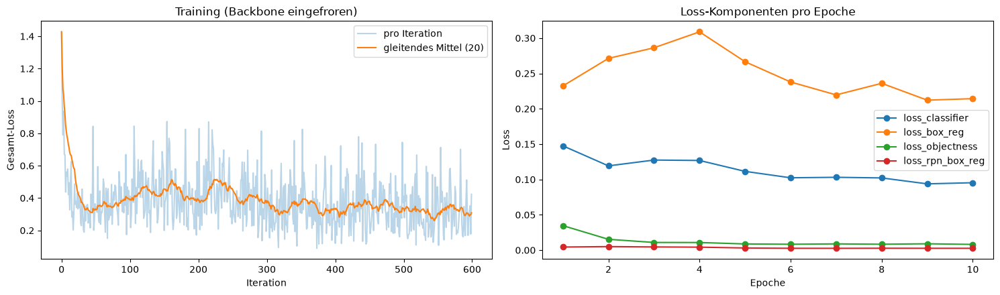

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].plot(frozen_history["loss"], alpha=0.3, label="pro Iteration")
axes[0].plot(frozen_history["loss"].rolling(20, min_periods=1).mean(), label="gleitendes Mittel (20)")
axes[0].set(xlabel="Iteration", ylabel="Gesamt-Loss", title="Training (Backbone eingefroren)")
axes[0].legend()
per_epoch = frozen_history.groupby("epoch").mean()
per_epoch.drop(columns="loss").plot(ax=axes[1], marker="o")
axes[1].set(xlabel="Epoche", ylabel="Loss", title="Loss-Komponenten pro Epoche")
plt.tight_layout()
plt.show()

In [12]:
test_targets = [testset[i][1] for i in range(len(testset))]
frozen_preds = evaluate(frozen_model)
coco_test = [coco_person[i] for i in test_idx]

print(f"AP@0.5 Testsplit – COCO-Modell (person): {average_precision(coco_test, test_targets):.3f}")
print(f"AP@0.5 Testsplit – fine-tuned (Backbone eingefroren): {average_precision(frozen_preds, test_targets):.3f}")
pd.concat({"COCO (person)": pr_table(coco_test, test_targets),
           "fine-tuned": pr_table(frozen_preds, test_targets)}, axis=1).round(3)

AP@0.5 Testsplit – COCO-Modell (person): 0.989
AP@0.5 Testsplit – fine-tuned (Backbone eingefroren): 0.987


COCO (person)                               fine-tuned               \
           Detektionen   TP  FP FN Precision Recall Detektionen   TP  FP  FN   
Schwelle                                                                       
0.3                219  141  78  0     0.644  1.000         154  136  18   5   
0.5                189  141  48  0     0.746  1.000         144  134  10   7   
0.8                156  139  17  2     0.891  0.986         138  130   8  11   

                           
         Precision Recall  
Schwelle                   
0.3          0.883  0.965  
0.5          0.931  0.950  
0.8          0.942  0.922

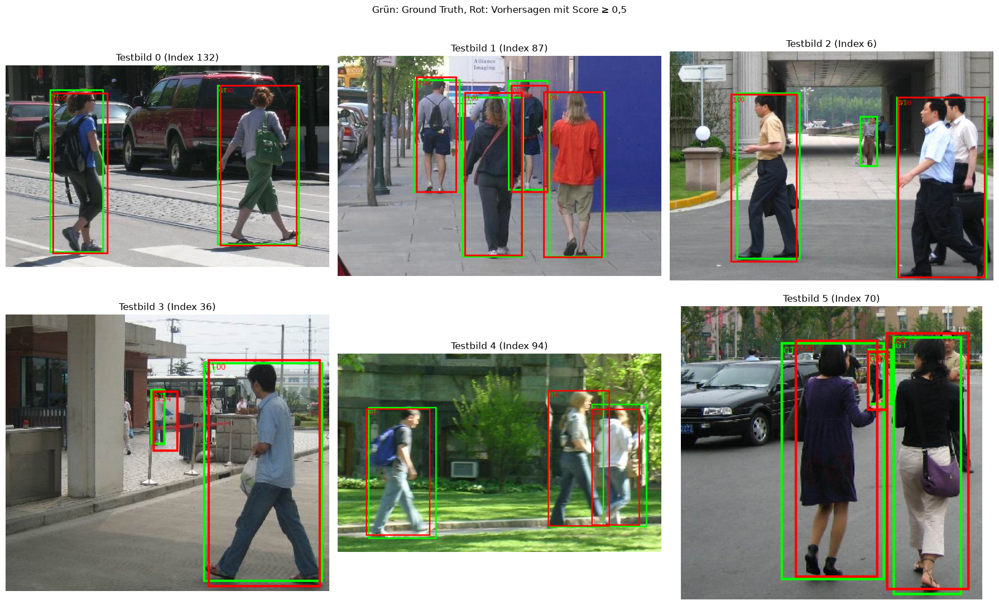

In [13]:
SCORE_THR = 0.5
show_ids = list(range(6))
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for ax, i in zip(axes.flat, show_ids):
    image, target = testset[i]
    pred = frozen_preds[i]
    keep = pred["scores"] >= SCORE_THR
    boxes = torch.cat([target["boxes"], pred["boxes"][keep]])
    labels = ["GT"] * len(target["boxes"]) + [f"{s:.2f}" for s in pred["scores"][keep]]
    colors = ["lime"] * len(target["boxes"]) + ["red"] * int(keep.sum())
    show_boxes(image, boxes, labels, colors, f"Testbild {i} (Index {test_idx[i]})", ax)
plt.suptitle("Grün: Ground Truth, Rot: Vorhersagen mit Score ≥ 0,5")
plt.tight_layout()
plt.show()

## 6. IoU auf Testbildern, verpasste und doppelte Detektionen

Pro Testbild werden die Vorhersagen mit Score ≥ 0,5 greedy (nach Score) den Ground-Truth-Boxen zugeordnet. *Doppelt* heißt: Die Vorhersage überlappt mit IoU ≥ 0,5 eine Person, die schon von einer besseren Box gematcht wurde. *Fehlalarm* heißt: keine Person mit IoU ≥ 0,5.

In [14]:
def per_image_report(preds, targets, ids, thr=SCORE_THR):
    rows = []
    for i in ids:
        pred, gt = preds[i], targets[i]["boxes"]
        keep = pred["scores"] >= thr
        boxes, scores = pred["boxes"][keep], pred["scores"][keep]
        tp, best = match(boxes, scores, gt)
        duplicates = int(((~tp) & (best >= 0.5)).sum())
        rows.append({
            "Testbild": i, "GT": len(gt), "Vorhersagen": len(boxes), "TP": int(tp.sum()),
            "IoU der Treffer": ", ".join(f"{v:.2f}" for v in best[tp].sort(descending=True).values),
            "verpasst": len(gt) - int(tp.sum()), "doppelt": duplicates,
            "Fehlalarm": int((~tp).sum()) - duplicates,
        })
    return pd.DataFrame(rows).set_index("Testbild")


report = per_image_report(frozen_preds, test_targets, range(len(testset)))
print(f"Über alle {len(testset)} Testbilder: {report['GT'].sum()} Personen, {report['TP'].sum()} getroffen, "
      f"{report['verpasst'].sum()} verpasst, {report['doppelt'].sum()} doppelt, {report['Fehlalarm'].sum()} Fehlalarme")
all_ious = []
for p, t in zip(frozen_preds, test_targets):
    keep = p["scores"] >= SCORE_THR
    tp, best = match(p["boxes"][keep], p["scores"][keep], t["boxes"])
    all_ious.append(best[tp])
all_ious = torch.cat(all_ious)
print(f"Mittlere IoU der Treffer: {all_ious.mean():.3f} (min {all_ious.min():.2f}, max {all_ious.max():.2f})")
report.head(8)

Über alle 50 Testbilder: 141 Personen, 134 getroffen, 7 verpasst, 0 doppelt, 10 Fehlalarme
Mittlere IoU der Treffer: 0.862 (min 0.54, max 0.97)


,GT,Vorhersagen,TP,IoU der Treffer,verpasst,doppelt,Fehlalarm
Testbild,,,,,,,
0,2,2,2,"0.93, 0.85",0,0,0
1,4,4,4,"0.91, 0.88, 0.84, 0.84",0,0,0
2,3,2,2,"0.96, 0.86",1,0,0
3,2,2,1,0.91,1,0,1
4,3,3,3,"0.89, 0.85, 0.82",0,0,0
5,3,3,3,"0.81, 0.78, 0.70",0,0,0
6,3,3,3,"0.96, 0.94, 0.90",0,0,0
7,3,3,3,"0.86, 0.80, 0.73",0,0,0


Bilder mit Fehlern: [2, 3, 10]


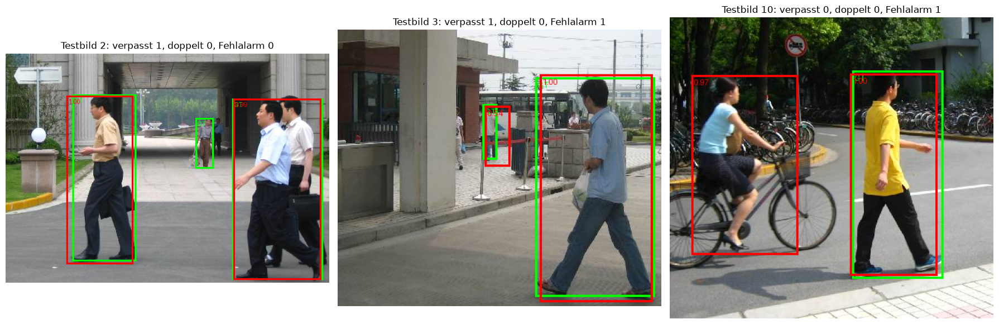

In [15]:
interesting = report[(report["verpasst"] > 0) | (report["doppelt"] > 0) | (report["Fehlalarm"] > 0)].index.tolist()[:3]
print("Bilder mit Fehlern:", interesting)
if interesting:
    fig, axes = plt.subplots(1, len(interesting), figsize=(6 * len(interesting), 6), squeeze=False)
    for ax, i in zip(axes[0], interesting):
        image, target = testset[i]
        pred = frozen_preds[i]
        keep = pred["scores"] >= SCORE_THR
        boxes = torch.cat([target["boxes"], pred["boxes"][keep]])
        labels = ["GT"] * len(target["boxes"]) + [f"{s:.2f}" for s in pred["scores"][keep]]
        colors = ["lime"] * len(target["boxes"]) + ["red"] * int(keep.sum())
        show_boxes(image, boxes, labels, colors, f"Testbild {i}: " + ", ".join(
            f"{k} {report.loc[i, k]}" for k in ("verpasst", "doppelt", "Fehlalarm")), ax)
    plt.tight_layout()
    plt.show()

**Diskussion:** Gefundene Personen werden genau lokalisiert: mittlere IoU 0,862, die meisten Treffer liegen über 0,8. Doppelte Detektionen gibt es bei Score ≥ 0,5 auf dem Testsplit keine, die NMS im Modell entfernt stark überlappende Boxen derselben Klasse zuverlässig. Die 7 verpassten Personen sind klein, weit entfernt oder stark verdeckt (Testbild 2: Person im Hintergrund unter der Durchfahrt). Testbild 3 zeigt, dass ein Fehler oft ein Lokalisierungsfehler ist: Die kleine Person hinter dem Pfeiler wird erkannt (Score 0,54), die Box ist aber zu groß, IoU < 0,5, und so zählt sie gleichzeitig als verpasst und als Fehlalarm. In Testbild 10 wird die Radfahrerin mit 0,97 erkannt, sie ist aber nicht als Fußgängerin annotiert: ein Fehlalarm durch die Labeldefinition, nicht durch das Modell.

Vergleich auf demselben Testsplit (Tabelle in Abschnitt 5): Das COCO-Modell findet bei Schwelle 0,5 alle 141 Personen (Recall 1,0), liefert aber 48 False Positives (Precision 0,746). Nach dem Fine-Tuning sind es nur noch 10 (Precision 0,931) bei Recall 0,950. Das Modell hat die Penn-Fudan-Definition von „Fußgänger“ gelernt und unterdrückt nicht gelabelte Personen, der Preis sind einige kleine Personen, die es jetzt verpasst. AP@0.5 bleibt praktisch gleich (0,989 vs. 0,987), weil der COCO-Detektor die Klasse `person` bereits kennt.

## 7. Optionale Erweiterung: eingefrorenes Backbone vs. Fine-Tuning der letzten Backbone-Stufen

Gleicher Split, gleiche Hyperparameter und gleiche Flip-Augmentation; einziger Unterschied ist `trainable_backbone_layers=3`.

In [16]:
torch.manual_seed(SEED)
random.seed(SEED)
tuned_model = build_model(trainable_backbone_layers=3)
tuned_history, tuned_time, tuned_params = train_detector(tuned_model)
tuned_preds = evaluate(tuned_model)

comparison = pd.DataFrame([
    {"Variante": "COCO vortrainiert (person)", "trainierbare Parameter (M)": 0, "Trainingszeit (s)": 0,
     "AP@0.5": average_precision(coco_test, test_targets)},
    {"Variante": "Head, Backbone eingefroren", "trainierbare Parameter (M)": frozen_params / 1e6,
     "Trainingszeit (s)": frozen_time, "AP@0.5": average_precision(frozen_preds, test_targets)},
    {"Variante": "Head + letzte 3 Backbone-Stufen", "trainierbare Parameter (M)": tuned_params / 1e6,
     "Trainingszeit (s)": tuned_time, "AP@0.5": average_precision(tuned_preds, test_targets)},
]).set_index("Variante")
for name, preds in (("Backbone eingefroren", frozen_preds), ("letzte 3 Stufen", tuned_preds)):
    row = pr_table(preds, test_targets, [SCORE_THR]).iloc[0]
    print(f"{name:22s} Schwelle 0.5: Precision {row['Precision']:.3f}, Recall {row['Recall']:.3f}")
comparison.round(3)

Epoche  1: Loss 0.8463


Epoche  2: Loss 0.8380


Epoche  3: Loss 0.7557


Epoche  4: Loss 0.7553


Epoche  5: Loss 0.6043


Epoche  6: Loss 0.4671


... (2 outputs left out)

Epoche  9: Loss 0.3523


Epoche 10: Loss 0.3893


Backbone eingefroren   Schwelle 0.5: Precision 0.931, Recall 0.950
letzte 3 Stufen        Schwelle 0.5: Precision 0.938, Recall 0.957


,trainierbare Parameter (M),Trainingszeit (s),AP@0.5
Variante,,,
COCO vortrainiert (person),0.000,0.000,0.989
"Head, Backbone eingefroren",14.515,13.756,0.987
Head + letzte 3 Backbone-Stufen,18.871,14.889,0.986


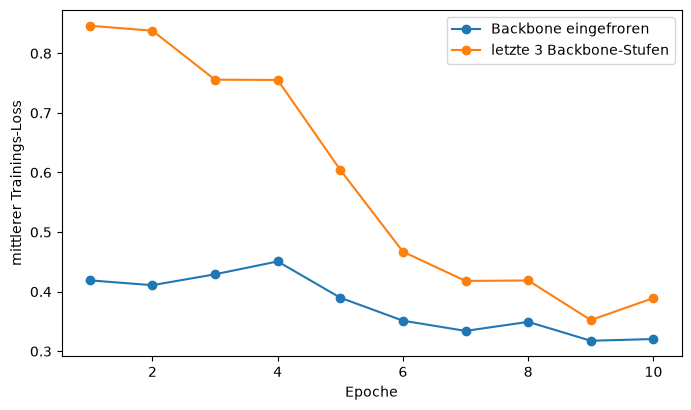

In [17]:
plt.figure(figsize=(8, 4.5))
for name, hist in (("Backbone eingefroren", frozen_history), ("letzte 3 Backbone-Stufen", tuned_history)):
    plt.plot(hist.groupby("epoch")["loss"].mean(), marker="o", label=name)
plt.xlabel("Epoche")
plt.ylabel("mittlerer Trainings-Loss")
plt.legend()
plt.show()

**Ergebnis:** Das Mittrainieren der letzten drei Backbone-Stufen bringt hier keinen Vorteil: AP@0.5 0,986 statt 0,987, Precision und Recall bei 0,5 nahezu gleich, dafür 4,4 M trainierbare Parameter mehr und etwas längere Trainingszeit (L40S: ca. 15 s statt 14 s; ein CPU-Testlauf brauchte 170 s statt 75 s). Der Loss startet doppelt so hoch (0,85 statt 0,42), weil sich die Backbone-Features erst an die neuen Gradienten anpassen, und erreicht nach 10 Epochen nicht ganz das Niveau des eingefrorenen Modells. Mit 120 Trainingsbildern und einer Klasse, die COCO schon enthält, reichen die vortrainierten Features. Das Backbone-Fine-Tuning ist auf der GPU nicht bitgenau reproduzierbar: Über zwei Läufe schwankte AP@0.5 zwischen 0,979 und 0,986.